# Quasar test: proper motions and parallaxes beyond Gaia's limit (PLAN Q1; Dustin's request)

Quasars have no measurable proper motion or parallax, so their measured PMs test our bias and error calibration at
magnitudes where the Gaia comparison is impossible (G > 21). Sample: DESI DR1 spectroscopic quasars
(`zall-pix-iron.fits`: SPECTYPE = QSO, ZWARN = 0, ZCAT_PRIMARY), matched by position (0.5 arcsec) to the PSF objects with
PMs in the combined v2 files of RA 000-063. Clean objects only (pm_quality == 0). Quasars that are Gaia sources have
the Gaia PM added back (as every Gaia source), so they are shown separately.

Caveat: quasar emission lines make their DCR differ from stars of the same colour (the DCR model is fitted on stars),
which can add scatter along the refraction direction; the redshift split below looks for it.

In [1]:
import os, sys
import numpy as np
import fitsio
import matplotlib.pyplot as plt
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from scipy.spatial import cKDTree
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps
from py_files.pm_analysis import COMBINED_DIR
ps.apply()
OUT = '../writeup/plots/'
ZCAT = '/global/cfs/cdirs/desi/public/dr1/spectro/redux/iron/zcatalog/v1/zall-pix-iron.fits'
CACHE = os.path.join(COMBINED_DIR, 'qso_desi_dr1.npz')
MATCH_ARCSEC = 0.5
COLS = ['ra', 'dec', 'ref_cat', 'type', 'pm_flag', 'pm_quality', 'flux_r', 'flux_g', 'flux_i',
        'pmra_no_plx', 'pmdec_no_plx', 'pmra_no_plx_ivar', 'pmdec_no_plx_ivar',
        'pmra_plx', 'pmdec_plx', 'pmra_plx_ivar', 'pmdec_plx_ivar', 'parallax_new', 'parallax_new_ivar',
        'pm_n_epochs', 'pm_baseline_days']

In [2]:
Z = fitsio.read(ZCAT, columns=['TARGET_RA', 'TARGET_DEC', 'Z', 'ZWARN', 'SPECTYPE', 'ZCAT_PRIMARY', 'DELTACHI2'])
Z = Z[(np.char.strip(Z['SPECTYPE'].astype(str)) == 'QSO') & (Z['ZWARN'] == 0) & Z['ZCAT_PRIMARY'] & (Z['TARGET_RA'] < 64.05)]
print(f'{len(Z):,} DESI DR1 quasars at RA < 64')

def unit(ra, dec):
    ra, dec = np.radians(ra), np.radians(dec)
    return np.c_[np.cos(dec) * np.cos(ra), np.cos(dec) * np.sin(ra), np.sin(dec)]

def match_slice(d):
    f = os.path.join(COMBINED_DIR, f'pm-{d}.fits')
    if not os.path.exists(f):
        return None
    q = np.flatnonzero((Z['TARGET_RA'] >= int(d) - 0.01) & (Z['TARGET_RA'] < int(d) + 1.01))
    if not len(q):
        return None
    T = fitsio.read(f, columns=COLS)
    dist, j = cKDTree(unit(T['ra'], T['dec'])).query(unit(Z['TARGET_RA'][q], Z['TARGET_DEC'][q]),
                                                      distance_upper_bound=np.radians(MATCH_ARCSEC / 3600))
    ok = np.isfinite(dist)
    out = {c: T[c][j[ok]] for c in COLS}
    out['z'] = Z['Z'][q[ok]]
    return out

if os.path.exists(CACHE):
    Q = dict(np.load(CACHE))
else:
    with ProcessPoolExecutor(16, mp_context=mp.get_context('fork')) as ex:
        parts = [p for p in ex.map(match_slice, [f'{d:03d}' for d in range(64)]) if p is not None]
    Q = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    # a quasar near a slice edge can match in two slices: keep one row per (ra, dec)
    _, u = np.unique(np.round(Q['ra'], 7) * 1000 + np.round(Q['dec'], 7), return_index=True)
    Q = {k: v[u] for k, v in Q.items()}
    np.savez(CACHE, **Q)
with np.errstate(all='ignore'):
    Q['r'] = 22.5 - 2.5 * np.log10(Q['flux_r'])
gaia = np.char.strip(Q['ref_cat'].astype(str)) == 'GE'
clean = (Q['pm_quality'] == 0) & (Q['pm_flag'] == 1)
print(f"{len(Q['ra']):,} matched PSF objects with PMs; clean {clean.sum():,} ({(clean & gaia).sum():,} Gaia sources)")

321,843 DESI DR1 quasars at RA < 64
277,812 matched PSF objects with PMs; clean 202,646 (74,468 Gaia sources)


In [3]:
def rs(v):
    v = v[np.isfinite(v)]
    return 1.4826 * np.median(np.abs(v - np.median(v))) if len(v) > 10 else np.nan

def stats(sel, model='no_plx'):
    s = '_' + model
    ra, de = Q['pmra' + s][sel], Q['pmdec' + s][sel]
    era, ede = 1 / np.sqrt(Q['pmra' + s + '_ivar'][sel]), 1 / np.sqrt(Q['pmdec' + s + '_ivar'][sel])
    out = dict(n=int(sel.sum()), mra=np.median(ra), mde=np.median(de),
               emra=1.2533 * rs(ra) / np.sqrt(sel.sum()), emde=1.2533 * rs(de) / np.sqrt(sel.sum()),
               sra=rs(ra), sde=rs(de), era=np.median(era), ede=np.median(ede),
               pra=rs(ra / era), pde=rs(de / ede),
               out5=np.mean((np.abs(ra / era) > 5) | (np.abs(de / ede) > 5)))
    if model == 'plx':
        p, ep = Q['parallax_new'][sel], 1 / np.sqrt(Q['parallax_new_ivar'][sel])
        out.update(mplx=np.median(p), emplx=1.2533 * rs(p) / np.sqrt(sel.sum()), splx=rs(p), eplx=np.median(ep), pplx=rs(p / ep))
    return out

EDGES = np.arange(17, 23.51, 0.5)
rows = []
for lo, hi in zip(EDGES[:-1], EDGES[1:]):
    sel = clean & ~gaia & (Q['r'] >= lo) & (Q['r'] < hi)
    if sel.sum() >= 500:
        rows.append(((lo + hi) / 2, stats(sel), stats(sel, 'plx')))
print('clean non-Gaia quasars, 4-parameter PMs (mas/yr); parallax from the 5-parameter fit (mas)')
print(f"{'r':>5s} {'N':>7s} {'median pmra':>14s} {'median pmdec':>14s} {'scatter':>11s} {'sigma':>11s} {'pull':>11s} {'>5sig':>6s} {'median plx':>13s} {'plx pull':>8s}")
for r, a, b in rows:
    print(f"{r:5.2f} {a['n']:7,d} {a['mra']:+7.3f}+-{a['emra']:.3f} {a['mde']:+7.3f}+-{a['emde']:.3f} "
          f"{a['sra']:5.2f}/{a['sde']:5.2f} {a['era']:5.2f}/{a['ede']:5.2f} {a['pra']:5.2f}/{a['pde']:5.2f} {a['out5']:6.2%} "
          f"{b['mplx']:+6.3f}+-{b['emplx']:.3f} {b['pplx']:8.2f}")
allf = clean & ~gaia & (Q['r'] < 23.5)
A = stats(allf)
print(f"all r < 23.5: N {A['n']:,}  median pmra {A['mra']:+.3f} +- {A['emra']:.3f}, pmdec {A['mde']:+.3f} +- {A['emde']:.3f} mas/yr; "
      f"pulls {A['pra']:.2f} / {A['pde']:.2f}")
G = stats(clean & gaia)
print(f"Gaia-source quasars (Gaia PM added back): N {G['n']:,}  median {G['mra']:+.3f} / {G['mde']:+.3f}; pulls {G['pra']:.2f} / {G['pde']:.2f}")

clean non-Gaia quasars, 4-parameter PMs (mas/yr); parallax from the 5-parameter fit (mas)
    r       N    median pmra   median pmdec     scatter       sigma        pull  >5sig    median plx plx pull
20.75   4,196  -0.172+-0.071  -0.205+-0.075  3.68/ 3.87  3.72/ 3.77  1.12/ 1.17  0.33% -0.664+-0.174     1.10
21.25  26,971  -0.156+-0.029  -0.078+-0.031  3.84/ 4.03  3.32/ 3.32  1.09/ 1.15  0.46% -0.793+-0.082     1.11
21.75  35,261  -0.285+-0.035  -0.163+-0.036  5.28/ 5.46  4.68/ 4.68  1.09/ 1.13  0.51% -0.910+-0.098     1.09
22.25  31,706  -0.363+-0.053  -0.296+-0.055  7.59/ 7.81  7.08/ 7.04  1.07/ 1.10  0.79% -1.025+-0.147     1.06
22.75  22,498  -0.304+-0.093  -0.360+-0.097 11.08/11.59 10.35/10.25  1.08/ 1.12  0.88% -1.224+-0.262     1.08
23.25   5,763  -0.812+-0.278  -0.782+-0.289 16.85/17.53 16.90/16.78  1.11/ 1.13  1.11% -1.714+-0.754     1.10
all r < 23.5: N 126,448  median pmra -0.266 +- 0.022, pmdec -0.197 +- 0.023 mas/yr; pulls 1.09 / 1.13
Gaia-source quasars (Gaia PM added bac

In [4]:
# redshift (emission lines through the bands -> DCR unlike stars) and declination (airmass)
for name, key, edges in [('redshift', 'z', [0, 1, 1.5, 2, 2.5, 3, 5]), ('Dec', 'dec', [-90, -40, -20, 0, 15, 40])]:
    print(f'by {name} (clean non-Gaia, r < 23.5):')
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = allf & (Q[key] >= lo) & (Q[key] < hi)
        if sel.sum() >= 50:
            a = stats(sel)
            print(f"  {lo:6.1f} - {hi:6.1f}: N {a['n']:7,d}  median {a['mra']:+.3f}+-{a['emra']:.3f} / {a['mde']:+.3f}+-{a['emde']:.3f}  pulls {a['pra']:.2f} / {a['pde']:.2f}")

by redshift (clean non-Gaia, r < 23.5):
     0.0 -    1.0: N   8,699  median -0.375+-0.072 / -0.253+-0.076  pulls 1.07 / 1.12
     1.0 -    1.5: N  29,869  median -0.322+-0.043 / -0.254+-0.045  pulls 1.10 / 1.13
     1.5 -    2.0: N  38,048  median -0.347+-0.042 / -0.283+-0.044  pulls 1.10 / 1.15
     2.0 -    2.5: N  28,418  median -0.222+-0.048 / -0.072+-0.051  pulls 1.06 / 1.10
     2.5 -    3.0: N  13,990  median -0.248+-0.070 / -0.254+-0.072  pulls 1.08 / 1.11
     3.0 -    5.0: N   7,404  median +0.203+-0.090 / +0.095+-0.092  pulls 1.14 / 1.14
by Dec (clean non-Gaia, r < 23.5):
   -20.0 -    0.0: N  65,318  median -0.068+-0.024 / +0.110+-0.024  pulls 1.09 / 1.12
     0.0 -   15.0: N  41,509  median -0.515+-0.045 / -0.500+-0.047  pulls 1.10 / 1.13
    15.0 -   40.0: N  19,621  median -0.967+-0.114 / -1.946+-0.130  pulls 1.07 / 1.12


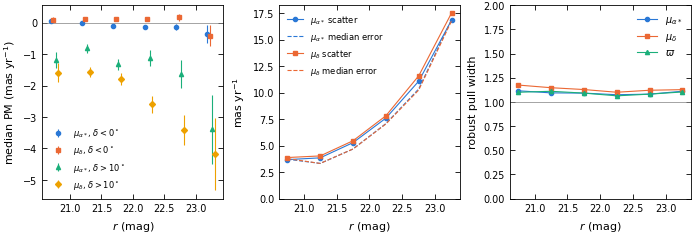

In [5]:
# figure: bias by declination (DCR of quasar emission lines grows with airmass; Dec > 10 is far from the CTIO zenith),
# scatter vs formal error, pull widths -- clean non-Gaia quasars
r = np.array([x[0] for x in rows])
A = [x[1] for x in rows]; B = [x[2] for x in rows]
fig, ax = plt.subplots(1, 3, figsize=(ps.PAGE, 2.4), constrained_layout=True)
k = 0
for dlab, dsel in [(r'$\delta < 0^\circ$', Q['dec'] < 0), (r'$\delta > 10^\circ$', Q['dec'] > 10)]:
    for comp, lab in [('pmra_no_plx', r'$\mu_{\alpha*}$'), ('pmdec_no_plx', r'$\mu_\delta$')]:
        xs, ys, es = [], [], []
        for lo, hi in zip(EDGES[:-1], EDGES[1:]):
            sel = clean & ~gaia & dsel & (Q['r'] >= lo) & (Q['r'] < hi)
            if sel.sum() >= 200:
                v = Q[comp][sel]
                xs.append((lo + hi) / 2 + 0.04 * (k - 1.5)); ys.append(np.median(v)); es.append(1.2533 * rs(v) / np.sqrt(len(v)))
        ax[0].errorbar(xs, ys, es, fmt=ps.MARKERS[k], ms=3, lw=0.8, color=ps.SERIES[k], label=f'{lab}, {dlab}')
        k += 1
ax[0].axhline(0, color='0.5', lw=0.5)
ax[0].set_ylabel(r'median PM (mas yr$^{-1}$)'); ax[0].legend(fontsize=6)
for k, (s, e, lab) in enumerate([('sra', 'era', r'$\mu_{\alpha*}$'), ('sde', 'ede', r'$\mu_\delta$')]):
    ax[1].plot(r, [a[s] for a in A], ps.MARKERS[k] + '-', ms=3, lw=0.8, color=ps.SERIES[k], label=lab + ' scatter')
    ax[1].plot(r, [a[e] for a in A], '--', lw=0.8, color=ps.SERIES[k], label=lab + ' median error')
ax[1].set_ylabel(r'mas yr$^{-1}$'); ax[1].set_ylim(0, None); ax[1].legend(fontsize=6)
for k, (vals, lab) in enumerate([([a['pra'] for a in A], r'$\mu_{\alpha*}$'), ([a['pde'] for a in A], r'$\mu_\delta$'),
                                 ([b['pplx'] for b in B], r'$\varpi$')]):
    ax[2].plot(r, vals, ps.MARKERS[k] + '-', ms=3, lw=0.8, color=ps.SERIES[k], label=lab)
ax[2].axhline(1, color='0.5', lw=0.5); ax[2].set_ylim(0, 2)
ax[2].set_ylabel('robust pull width'); ax[2].legend(fontsize=7)
for a in ax:
    a.set_xlabel('$r$ (mag)')
plt.savefig(OUT + 'qso_pm.pdf')

In [6]:
# bias by declination x magnitude, and by redshift (sign flip at z > 3: Lyman-alpha forest in g -> DCR unlike lower z)
redges = [20.5, 21.5, 22.5, 23.5]
for comp in ['pmra_no_plx', 'pmdec_no_plx', 'parallax_new']:
    print(comp)
    for dlo, dhi in [(-20, -10), (-10, 0), (0, 10), (10, 20), (20, 35)]:
        cells = []
        for a, b in zip(redges[:-1], redges[1:]):
            sel = allf & (Q['dec'] >= dlo) & (Q['dec'] < dhi) & (Q['r'] >= a) & (Q['r'] < b)
            v = Q[comp][sel]
            cells.append(f'{np.median(v):+6.2f}({1.2533 * rs(v) / np.sqrt(len(v)):.2f})' if len(v) > 100 else '     --     ')
        print(f'  Dec {dlo:4d}..{dhi:3d}', ' '.join(cells))
print('by redshift: pmdec at Dec < 0 / Dec > 10, parallax (all Dec)')
for a, b in [(0, 1), (1, 1.5), (1.5, 2), (2, 2.5), (2.5, 3), (3, 5)]:
    s = allf & (Q['z'] >= a) & (Q['z'] < b)
    f = lambda sel, c: f'{np.median(Q[c][sel]):+.2f}({1.2533 * rs(Q[c][sel]) / np.sqrt(sel.sum()):.2f})'
    print(f'  z {a}-{b}: N {s.sum():6,d}', f(s & (Q['dec'] < 0), 'pmdec_no_plx'), f(s & (Q['dec'] > 10), 'pmdec_no_plx'), f(s, 'parallax_new'))

pmra_no_plx
  Dec  -20..-10  -0.04(0.05)  -0.15(0.06)  -0.05(0.17)
  Dec  -10..  0  +0.03(0.04)  -0.10(0.04)  -0.22(0.11)
  Dec    0.. 10  -0.30(0.05)  -0.49(0.06)  -0.36(0.17)
  Dec   10.. 20  -0.94(0.17)  -1.84(0.19)  -1.74(0.59)
  Dec   20.. 35  -0.83(0.16)  -0.54(0.20)  -2.11(0.58)
pmdec_no_plx
  Dec  -20..-10  +0.00(0.05)  +0.17(0.06)  -0.09(0.18)
  Dec  -10..  0  +0.16(0.04)  +0.10(0.04)  +0.16(0.12)
  Dec    0.. 10  -0.11(0.05)  -0.39(0.06)  -0.56(0.18)
  Dec   10.. 20  -1.39(0.20)  -2.14(0.21)  -3.16(0.60)
  Dec   20.. 35  -1.69(0.19)  -2.12(0.23)  -3.97(0.66)
parallax_new
  Dec  -20..-10  -0.95(0.15)  -1.25(0.16)  -1.39(0.49)
  Dec  -10..  0  -0.78(0.11)  -0.90(0.12)  -0.76(0.36)
  Dec    0.. 10  -0.66(0.14)  -0.68(0.16)  -1.86(0.49)
  Dec   10.. 20  -1.35(0.33)  -0.97(0.38)  -3.01(1.10)
  Dec   20.. 35  -0.10(0.42)  -1.44(0.48)  +0.77(1.43)
by redshift: pmdec at Dec < 0 / Dec > 10, parallax (all Dec)
  z 0-1: N  8,699 +0.08(0.08) -1.65(0.28) -0.61(0.20)
  z 1-1.5: N 29,869 +0